# Double well: tuning the final SSISDE fit

$$dX_t=(0.5X_t-X_t^3)\,dt+(1+0.25X_t^2)\,dB_t^P.$$

The simulation, diffusion estimate and recovered noise paths are the same as in the original double-well experiment. For each of Method 1, Method 2 and ODE2, compare the existing SSISDE settings with tuned settings.

The search tests 30 configurations: smaller polynomial libraries, weaker regularization, Elastic Net, Lasso, Ridge thresholds and selection with or without the one-standard-error rule. Each candidate trains on the first 80% of the coarse increments; its error on the last 20% selects the configuration. Inner time-series cross-validation stays within the training segment. The selected configuration is then refitted on the whole path.

True drift and diffusion are used only to report errors after selection. Validation here is conditional on the recovered noise: it does not independently validate the upstream noise-recovery method. Baseline and tuned plots retain the same recovered noise for each method.


In [1]:
from pathlib import Path
import os
import sys

if not (3, 10) <= sys.version_info[:2] < (3, 13):
    raise RuntimeError("The original dependency pins require Python 3.10–3.12; use the local .venv or a compatible Colab runtime.")

def _find_project():
    for candidate in [Path.cwd(), *Path.cwd().parents, Path('/content/SSISDE')]:
        if (candidate / 'models/stochastic_sindy.py').is_file() and (candidate / 'requirements.txt').is_file():
            return candidate
    return None

PROJECT_ROOT = _find_project()
if PROJECT_ROOT is None:
    import importlib.util
    try:
        _in_colab = importlib.util.find_spec('google.colab') is not None
    except ModuleNotFoundError:
        _in_colab = False
    if not _in_colab:
        raise FileNotFoundError("Open this notebook from the SSISDE checkout so its Python scripts are available.")

    def _download_private_project():
        from getpass import getpass
        from io import BytesIO
        from urllib.request import Request, urlopen
        from zipfile import ZipFile
        token = getpass('GitHub token (read-only Contents access to SSISDE): ')
        try:
            request = Request(
                'https://api.github.com/repos/munawarali93/SSISDE/zipball/main',
                headers={'Authorization': f'Bearer {token}', 'Accept': 'application/vnd.github+json'},
            )
            with urlopen(request, timeout=120) as response:
                archive_bytes = response.read()
        finally:
            token = None
            request = None
        destination = Path('/content/SSISDE')
        with ZipFile(BytesIO(archive_bytes)) as archive:
            for member in archive.infolist():
                relative = Path(*Path(member.filename).parts[1:])
                if member.is_dir() or not relative.parts:
                    continue
                target = (destination / relative).resolve()
                if not target.is_relative_to(destination.resolve()):
                    raise ValueError('Unsafe archive path')
                target.parent.mkdir(parents=True, exist_ok=True)
                target.write_bytes(archive.read(member))
        return destination

    PROJECT_ROOT = _download_private_project()

os.chdir(PROJECT_ROOT / 'experiments/double_well/ssisde_tuning')
print(f'Project: {PROJECT_ROOT}')
print(f'Python: {sys.version.split()[0]}')

sys.path.insert(0, str(PROJECT_ROOT))
RESULTS = PROJECT_ROOT / 'outputs/double_well/ssisde_tuning'
RESULTS.mkdir(parents=True, exist_ok=True)


Project: /Users/munawarali/Documents/GitHub/SSISDE
Python: 3.11.13


##Install libraries

In [2]:
# Install into the selected kernel before importing scientific libraries.
# The four original version pins are retained in requirements.txt.
import subprocess
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', str(PROJECT_ROOT / 'requirements.txt')])



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: /Users/munawarali/Documents/GitHub/SSISDE/.venv/bin/python -m pip install --upgrade pip


0

##Import libraries

In [3]:
import numpy as np
import math
import matplotlib.pyplot as plt
import pysindy as ps
import random
import iisignature
from sklearn import linear_model
from sklearn.metrics import mean_squared_error
from tqdm import tqdm
from sklearn.linear_model import Lasso, ElasticNet
from sklearn.model_selection import TimeSeriesSplit
import json
from threadpoolctl import threadpool_limits
from models.diffusion_tuning import fit_diffusion


Matplotlib is building the font cache; this may take a moment.


/Users/munawarali/Documents/GitHub/SSISDE/.venv/lib/python3.11/site-packages/pysindy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound


##Defining parameters and simulating noise

In [4]:
from data_generation.double_well import generate_data
N, T, S0, seed = 100000, 1.0, 1.0, 3
t, dt, S_, W_, mu_exact_, sigma_exact_ = generate_data(N, T, S0, seed)
fine_dt = dt


##Simulating primary processes

## $$dS_t = \mu(S_t)dt + \sigma(S_t)dB_t$$

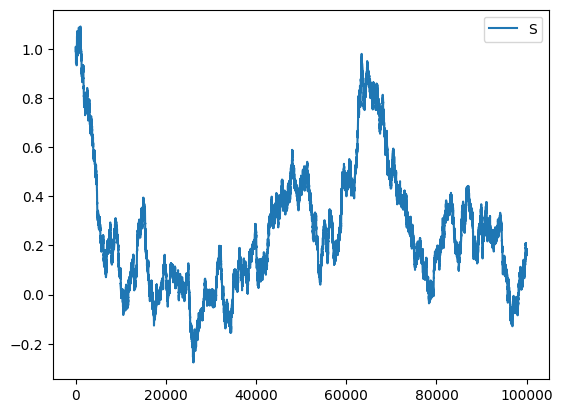

In [5]:
plt.plot(S_, label="S")
plt.legend()
plt.show()

##compute quadratic variation

  0%|          | 0/100000 [00:00<?, ?it/s]

  9%|▊         | 8630/100000 [00:00<00:01, 82712.77it/s]

 17%|█▋        | 17345/100000 [00:00<00:00, 85274.10it/s]

 26%|██▌       | 25877/100000 [00:00<00:00, 77428.37it/s]

 34%|███▎      | 33695/100000 [00:00<00:00, 67149.45it/s]

...

 93%|█████████▎| 93115/100000 [00:02<00:00, 22862.17it/s]

 95%|█████████▌| 95391/100000 [00:02<00:00, 22186.75it/s]

 98%|█████████▊| 97601/100000 [00:02<00:00, 21566.26it/s]

100%|█████████▉| 99750/100000 [00:02<00:00, 21039.70it/s]

100%|██████████| 100000/100000 [00:02<00:00, 34835.97it/s]

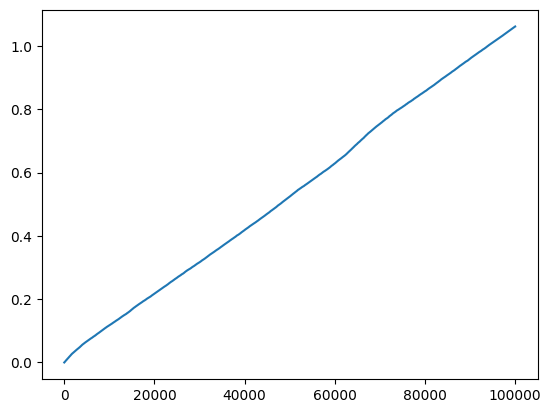

In [6]:
from models.quadratic_variation import estimate_quadratic_variation
QV, dQV, diff_method = estimate_quadratic_variation(S_, t)
plt.plot(QV)

## Approximating $\sigma$

Use the existing degree-4 variance library. Select SR3 settings on the last
20% of observations, then refit on the full path. The true diffusion is used
only to report error. All subsequent stages follow Black-Scholes.

In [7]:
thresholds = [0.01, 0.1, 0.3, 1.0, 3.0, 10.0]
nus = [0.1, 0.5, 2.0]
model, sigma_settings, sigma_search = fit_diffusion(S_, t, dQV, thresholds, nus)
sigma_equation = model.equations(precision=8)[0]
print('sigma^2(X) =', sigma_equation)
print(sigma_settings)
(RESULTS / 'diffusion_tuning.json').write_text(json.dumps(sigma_search, indent=2))

sigma^2(X) = 0.98821428 1 + 0.02488806 X + 0.51636376 X^2
{'threshold': 3.0, 'nu': 0.5, 'validation_mse': 1.729465164559883, 'max_iter': 10000, 'tol': 1e-08, 'terms': 3, 'converged': True, 'full_fit_converged': True}


3005

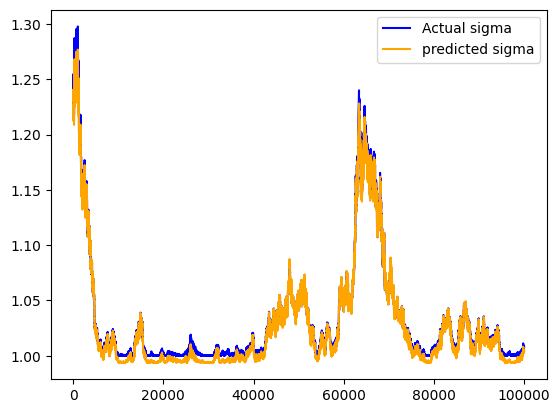

In [8]:
sigma_pred_ = np.sqrt(model.predict(S_.reshape(-1, 1)))
sigma_pred_ = np.array(sigma_pred_)
plt.plot(sigma_exact_, label="Actual sigma",color="blue")
plt.plot(sigma_pred_,label="predicted sigma", color="orange")
plt.legend()
plt.show()

In [9]:
from models.diffusion_derivatives import diffusion_derivatives
sigma_prime_, sigma_2prime_, sigma_3prime_ = diffusion_derivatives(sigma_pred_, S_, diff_method)


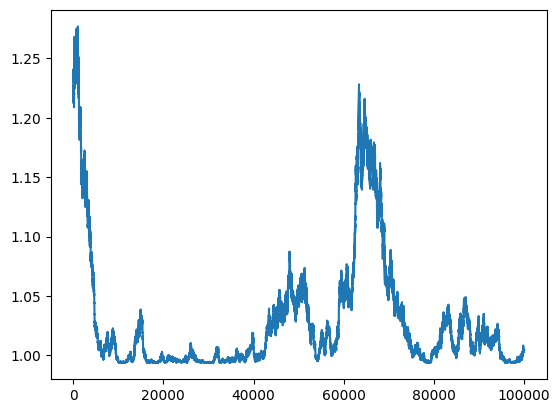

In [10]:
plt.plot(sigma_pred_)

##Q Brownian motion

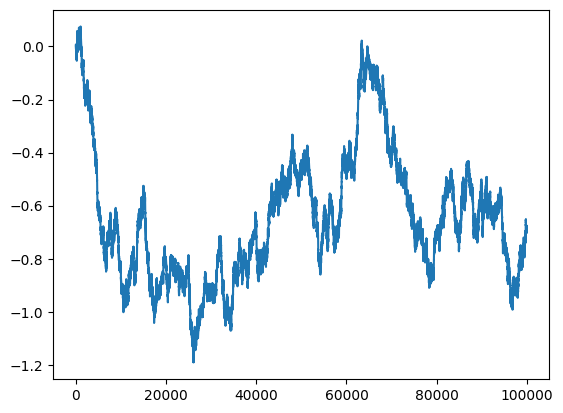

In [11]:
from models.q_brownian_motion import recover_q_noise
BQ_ = recover_q_noise(S_, sigma_pred_)
plt.plot(BQ_)

#Fit signature model

In [12]:
keep_cols = [0, 1, 3, 4, 5, 13]

  0%|          | 0/1000 [00:00<?, ?it/s]

 20%|█▉        | 196/1000 [00:00<00:00, 1957.71it/s]

 40%|████      | 402/1000 [00:00<00:00, 2012.94it/s]

 60%|██████    | 605/1000 [00:00<00:00, 2019.83it/s]

 81%|████████  | 810/1000 [00:00<00:00, 2028.39it/s]

100%|██████████| 1000/1000 [00:00<00:00, 2028.20it/s]

0.00011674972607588812

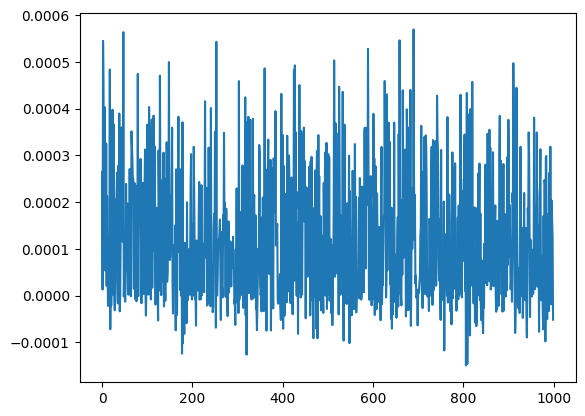

In [13]:
from models.signature_regression import fit_signature
M = 100
K = int(N/M)
l21 = fit_signature(S_, BQ_, t, keep_cols, M)
plt.plot(l21)
np.mean(l21)

In [14]:
from data_generation.coarse_graining import coarse_grain
sigma_pred, mu_exact, S, BQ, W, sigma_exact = coarse_grain(
    S_, BQ_, W_, mu_exact_, sigma_exact_, sigma_pred_, M, K,
)


In [15]:
from models.coarse_diffusion_derivatives import coarse_diffusion_derivatives
sigma_prime, sigma_2prime, sigma_3prime = coarse_diffusion_derivatives(sigma_pred, S, diff_method)


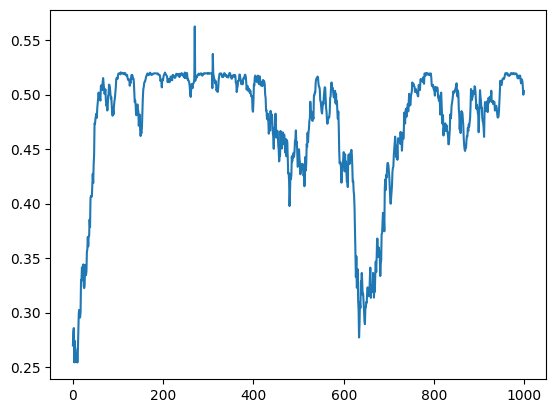

In [16]:
plt.plot(sigma_2prime)

## Predicting $\mu(X_t)$ by tuncating up to level-2 of iterated integrals

In [17]:
from models.drift_coefficients import drift_coefficients
mu_0, a, b, b_ = drift_coefficients(mu_exact, sigma_pred, sigma_prime, sigma_2prime, l21)


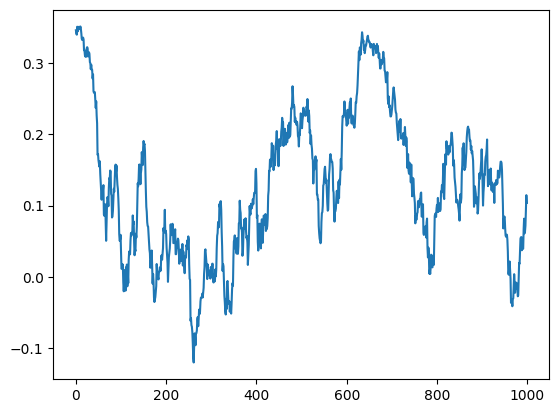

In [18]:
#plt.plot(b)
plt.plot(a)

In [19]:
from models.drift_recovery import recover_drift
mu_pred1, mu_pred2 = recover_drift(S, a, b, b_, mu_0)


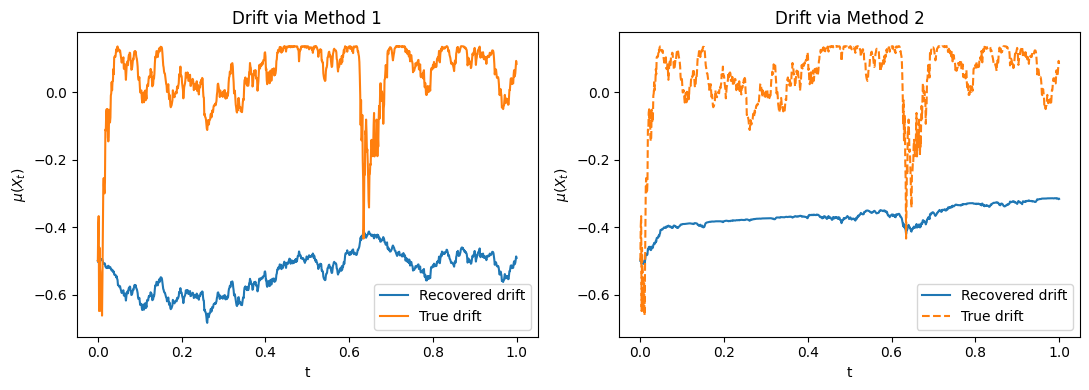

In [20]:
t_ = np.linspace(0, T, K)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t_, mu_pred1, label="Recovered drift")
axes[0].plot(t_, mu_exact, label="True drift")
axes[0].set_title("Drift via Method 1")
axes[0].set_xlabel("t")
axes[0].set_ylabel("$\mu(X_t)$")
axes[0].legend()
axes[1].plot(t_, mu_pred2, label="Recovered drift")
axes[1].set_title("Drift via Method 2")
axes[1].plot(t_, mu_exact, '--', label="True drift")
axes[1].set_xlabel("t")
axes[1].set_ylabel("$\mu(X_t)$")
axes[1].legend()
axes[1].set_ylim(axes[0].get_ylim())

plt.tight_layout()
plt.savefig("Drift_via_Euler_BS.png", bbox_inches='tight', dpi=300)
plt.show()

## Drift recovery from ODE2

Use the same ODE2 recurrence as Black-Scholes. Supply the initial drift and
the known initial spatial slope for this process. This is a drift comparison;
noise recovery below uses Method 1.

In [21]:
lambda_0 = 0.5 - 3*S0**2
from models.drift_recovery_from_ODE2 import recover_drift_ode2
mu_pred11, lamda_pred = recover_drift_ode2(S, sigma_pred, sigma_prime, sigma_2prime, mu_0, lambda_0)


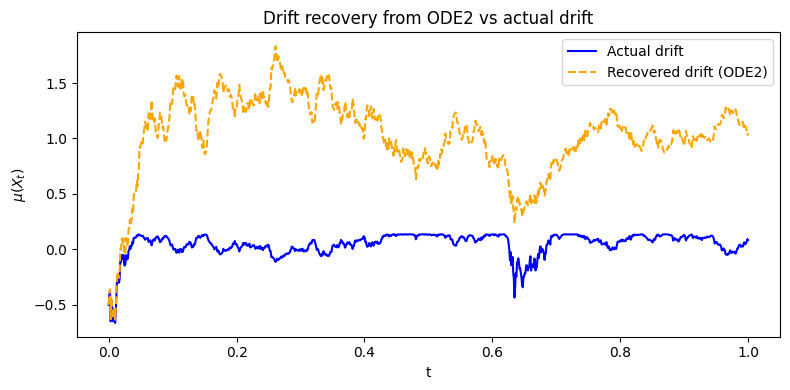

ODE2 drift MSE: 1.07893
ODE2 drift RMSE: 1.03872


In [22]:
plt.figure(figsize=(8, 4))
plt.plot(t_, mu_exact, label="Actual drift", color="blue")
plt.plot(t_, mu_pred11, '--', label="Recovered drift (ODE2)", color="orange")
plt.xlabel("t")
plt.ylabel(r"$\mu(X_t)$")
plt.title("Drift recovery from ODE2 vs actual drift")
plt.legend()
plt.tight_layout()
plt.savefig("Drift_via_ODE2_BS.png", bbox_inches='tight', dpi=300)
plt.show()

ode2_drift_mse = mean_squared_error(mu_exact, mu_pred11)
print(f"ODE2 drift MSE: {ode2_drift_mse:.6g}")
print(f"ODE2 drift RMSE: {np.sqrt(ode2_drift_mse):.6g}")


## Drift comparison across all methods

Method 1: drift RMSE = 0.591795
Method 2: drift RMSE = 0.423998
ODE2: drift RMSE = 1.03872


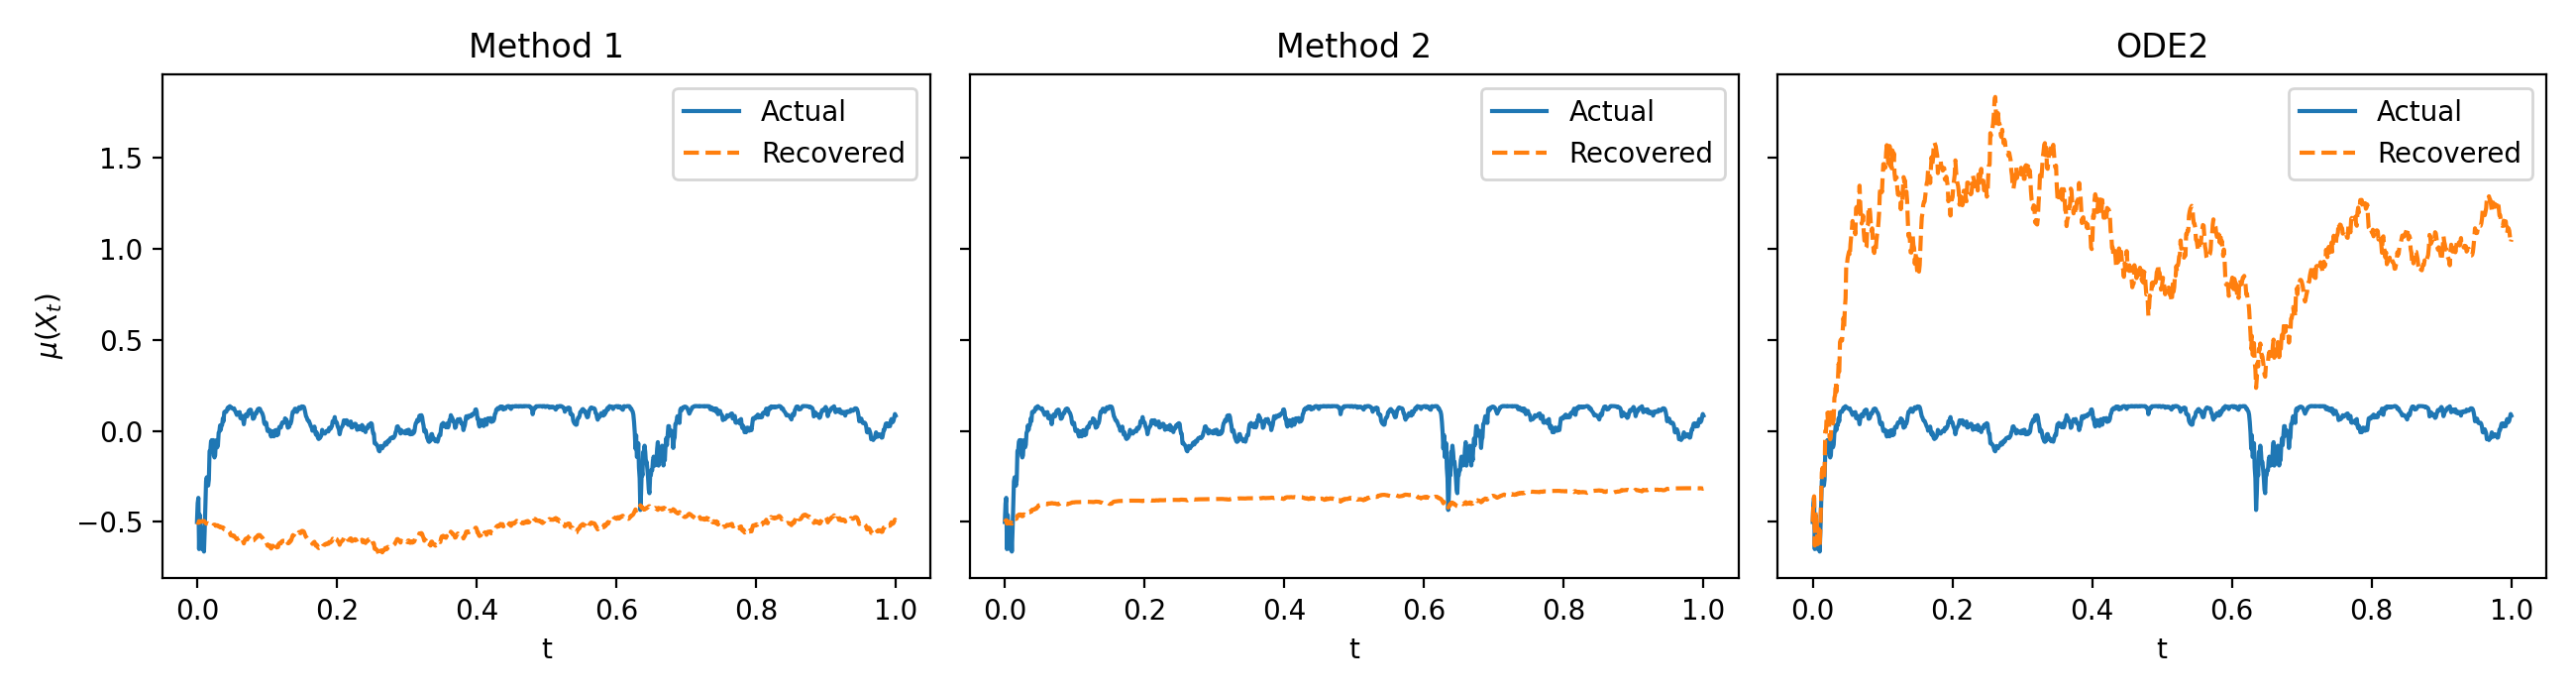

In [ ]:
t_ = np.linspace(0, T, K)
drift_estimates = {'Method 1': mu_pred1, 'Method 2': mu_pred2, 'ODE2': mu_pred11}
drift_rmse = {}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, (name, estimate) in zip(axes, drift_estimates.items()):
    drift_rmse[name] = float(np.sqrt(np.mean((estimate - mu_exact)**2)))
    ax.plot(t_, mu_exact, label='Actual')
    ax.plot(t_, estimate, '--', label='Recovered')
    ax.set_title(name)
    ax.set_xlabel('t')
    ax.legend()
    print(f"{name}: drift RMSE = {drift_rmse[name]:.6g}")
axes[0].set_ylabel(r'$\mu(X_t)$')
fig.tight_layout()
fig.savefig('drift_comparison.png', dpi=200)
plt.show()


##Predicting P-Brownian motion

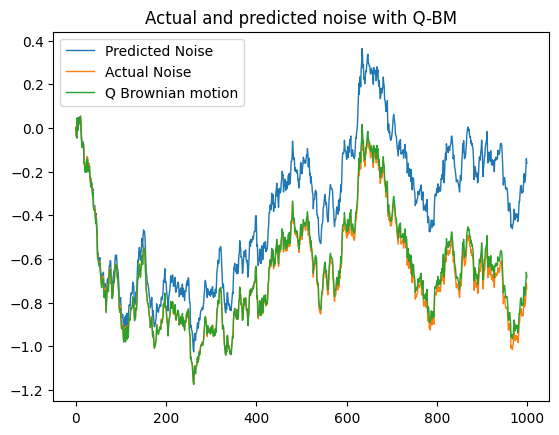

In [23]:
from models.p_brownian_motion import recover_p_noise
model = "Psi_approx_BS"
BP, dt, t = recover_p_noise(BQ, mu_pred1, sigma_pred, T)
plt.plot(BP, label="Predicted Noise", linewidth=1)
plt.plot(W, label="Actual Noise", linewidth=1)
plt.plot(BQ, label="Q Brownian motion", linewidth=1)
plt.title("Actual and predicted noise with Q-BM")
plt.legend()
plt.savefig(f"{model}_Actual and predicted noise with Q-BM.png", bbox_inches='tight', dpi=300)
plt.show()

### Method 1

Fitting baseline


Fitting elasticnet_mu1_sigma2_1seTrue


Fitting elasticnet_mu1_sigma2_1seFalse


Fitting lasso_mu1_sigma2_1seTrue


...

Fitting ridge_mu1000.0_threshold0.0001


Fitting ridge_mu1000.0_threshold0.005


Fitting unthresholded_mu3_sigma2


**Baseline: drift from Method 1**

MSE: 3.343e-08
μ(X) = -0.523664
σ(X) = 0.993702 + 0.019956*X + 0.226928*X^2
[CV best] alpha=0.00131, l1_ratio (rho)=0.40


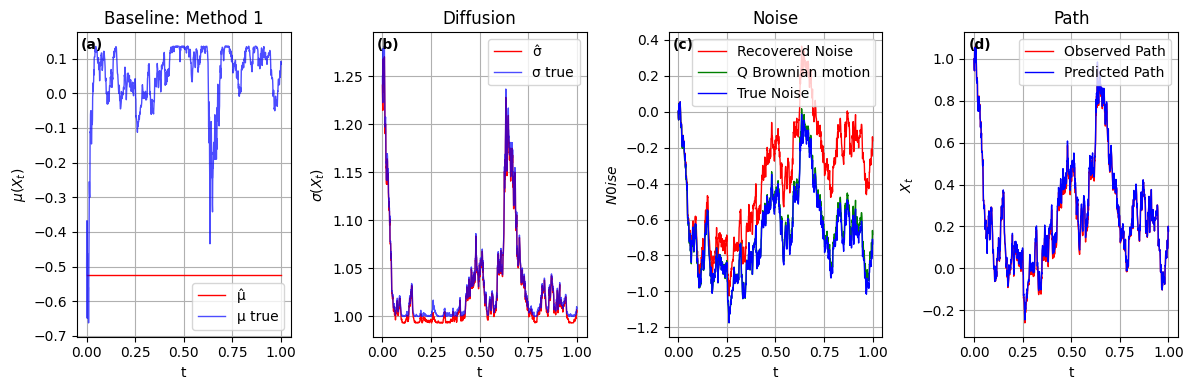

**Tuned: drift from Method 1**

MSE: 3.343e-08
μ(X) = -0.523664
σ(X) = 0.993702 + 0.019956*X + 0.226928*X^2
[CV best] alpha=0.00562, l1_ratio (rho)=0.05


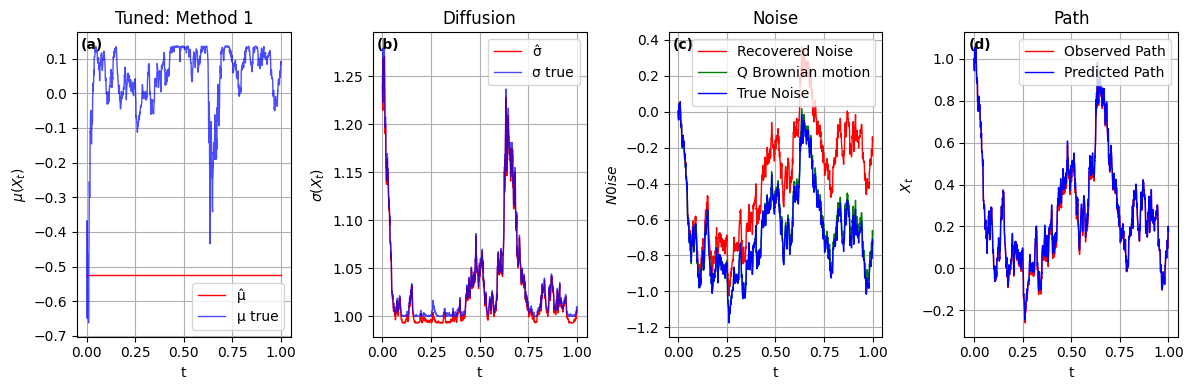

### Method 2

Fitting baseline


Fitting elasticnet_mu1_sigma2_1seTrue


Fitting elasticnet_mu1_sigma2_1seFalse


Fitting lasso_mu1_sigma2_1seTrue


...

Fitting ridge_mu1000.0_threshold0.0001


Fitting ridge_mu1000.0_threshold0.005


Fitting unthresholded_mu3_sigma2


**Baseline: drift from Method 2**

MSE: 2.904e-08
μ(X) = -0.357545
σ(X) = 0.994025 + 0.0178146*X + 0.229962*X^2
[CV best] alpha=0.000873, l1_ratio (rho)=0.40


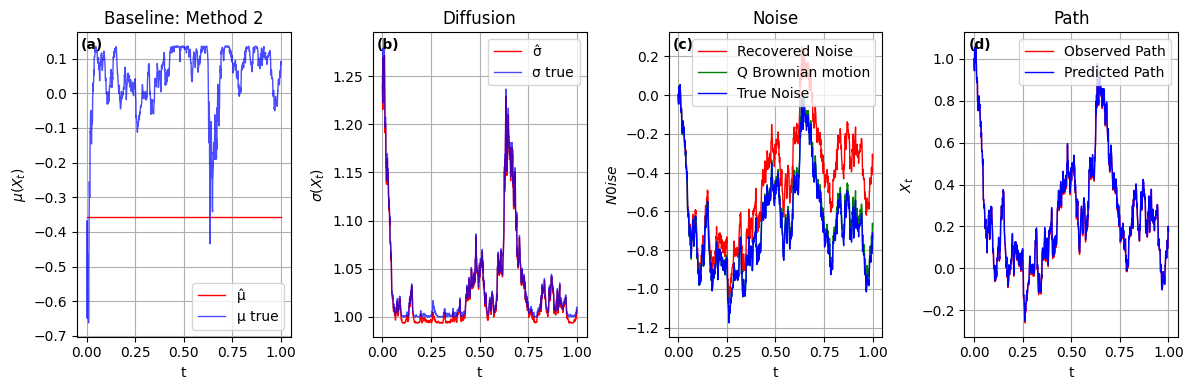

**Tuned: drift from Method 2**

MSE: 2.904e-08
μ(X) = -0.357545
σ(X) = 0.994025 + 0.0178146*X + 0.229962*X^2
[CV best] alpha=0.000873, l1_ratio (rho)=0.40


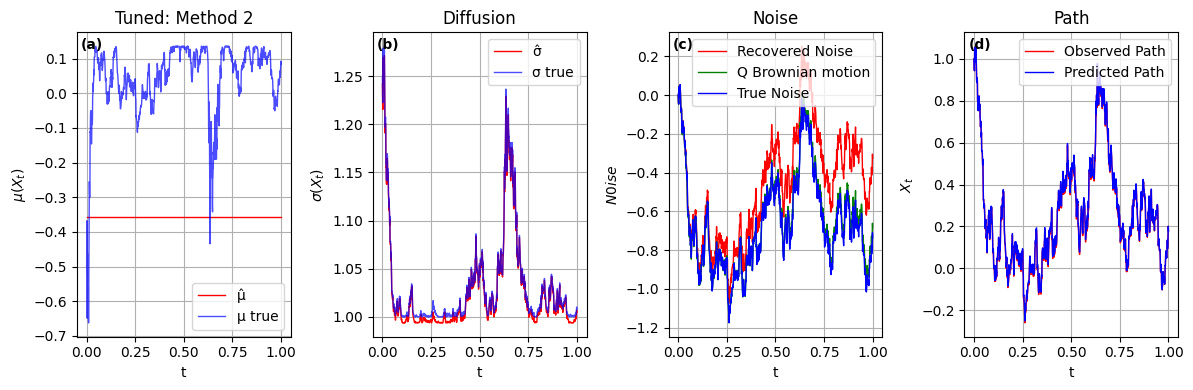

### ODE2

Fitting baseline


Fitting elasticnet_mu1_sigma2_1seTrue


Fitting elasticnet_mu1_sigma2_1seFalse


Fitting lasso_mu1_sigma2_1seTrue


...

Fitting ridge_mu1000.0_threshold0.0001


Fitting ridge_mu1000.0_threshold0.005


Fitting unthresholded_mu3_sigma2


**Baseline: drift from ODE2**

MSE: 1.449e-07
μ(X) = 1.03809
σ(X) = 0.994996 + 0.00919418*X + 0.245545*X^2
[CV best] alpha=0.000582, l1_ratio (rho)=0.40


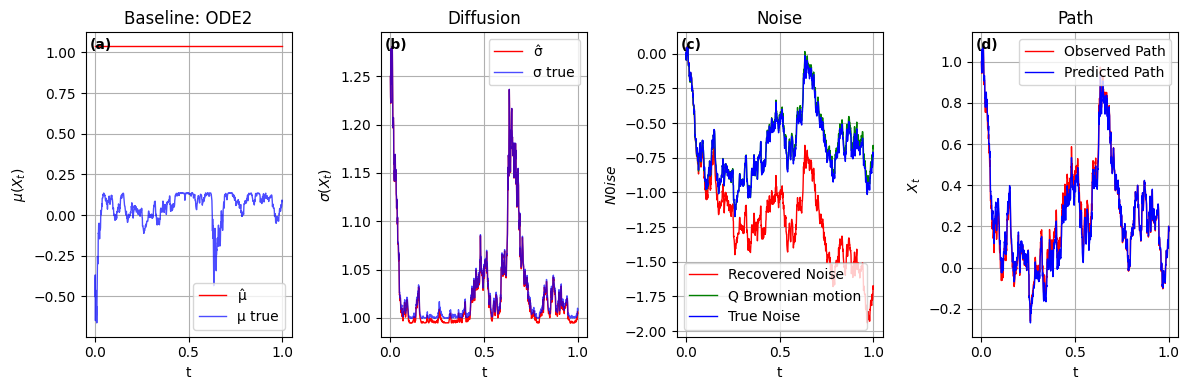

**Tuned: drift from ODE2**

MSE: 3.651e-08
μ(X) = 1.36148 + -1.66899*X + 1.74124*X^2 + -1.53629*X^3
σ(X) = 0.993855 + 0.0184709*X + 0.229691*X^2
[CV best] alpha=1e-05, l1_ratio (rho)=0.05


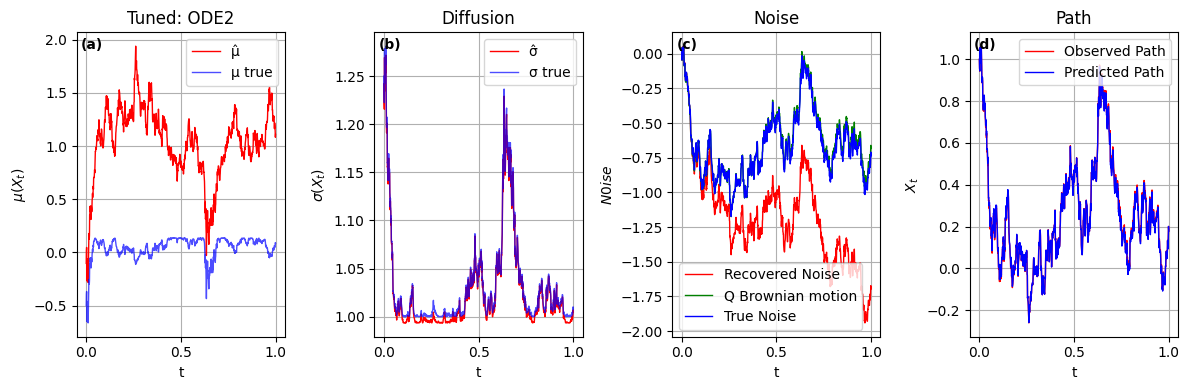

| Noise from | Baseline drift RMSE | Tuned drift RMSE | Baseline diffusion RMSE | Tuned diffusion RMSE |
|---|---:|---:|---:|---:|
| Method 1 | 0.579673 | 0.579673 | 0.00468819 | 0.00468819 |
| Method 2 | 0.417465 | 0.417465 | 0.0044355 | 0.0044355 |
| ODE2 | 0.997516 | 1.0401 | 0.00358195 | 0.00449907 |

In [24]:
from models.stochastic_sindy_tuning import tune_stochastic_sindy
from models.p_brownian_motion import recover_p_noise
from IPython.display import Markdown, display

recovered_drifts = {"Method 1": mu_pred1, "Method 2": mu_pred2, "ODE2": mu_pred11}
baseline_models, tuned_models, noise_paths = {}, {}, {}
tuning_results, saved_paths = {}, {}

def error(estimate, actual):
    return float(np.sqrt(np.mean((np.asarray(estimate).ravel()-np.asarray(actual).ravel())**2)))

for method_name, recovered_drift in recovered_drifts.items():
    display(Markdown(f"### {method_name}"))
    BP_method, dt_method, _ = recover_p_noise(BQ, recovered_drift, sigma_pred, T)
    noise_paths[method_name] = BP_method
    tuned, baseline, selection, trials = tune_stochastic_sindy(S, BP_method, dt_method)
    baseline_models[method_name], tuned_models[method_name] = baseline, tuned
    values = {"selection": selection, "trials": trials,
              "input_drift_rmse": error(recovered_drift, mu_exact),
              "noise_rmse": error(BP_method, W)}
    key = method_name.lower().replace(" ", "_")
    saved_paths[f"BP_{key}"] = BP_method
    for label, fitted in [("Baseline", baseline), ("Tuned", tuned)]:
        display(Markdown(f"**{label}: drift from {method_name}**"))
        fitted.show()
        fitted.plot_results(S, BP_method, BQ, W, mu_true=mu_exact, si_true=sigma_exact,
                            output_prefix=f"{key}_{label.lower()}",
                            drift_title=f"{label}: {method_name}")
        values[label.lower()] = {
            "drift_rmse": error(fitted.mu(S), mu_exact),
            "diffusion_rmse": error(fitted.si(S), sigma_exact),
            "increment_mse": fitted.mse,
            "mu": fitted._fmt_poly(fitted.mu_c), "sigma": fitted._fmt_poly(fitted.si_c),
            "mu_coefficients": fitted.mu_c.tolist(), "sigma_coefficients": fitted.si_c.tolist(),
            "alpha": fitted.best_a, "rho": fitted.best_r,
        }
        saved_paths[f"mu_{key}_{label.lower()}"] = fitted.mu(S)
        saved_paths[f"sigma_{key}_{label.lower()}"] = fitted.si(S)
    tuning_results[method_name] = values
    (RESULTS / "tuning_results.json").write_text(json.dumps(tuning_results, indent=2, allow_nan=False))

np.savez_compressed(RESULTS / "tuning_paths.npz", S=S, BQ=BQ, W=W, mu_exact=mu_exact,
                    sigma_exact=sigma_exact, sigma_pred=sigma_pred, dt=dt, **saved_paths)
rows = ["| Noise from | Baseline drift RMSE | Tuned drift RMSE | Baseline diffusion RMSE | Tuned diffusion RMSE |",
        "|---|---:|---:|---:|---:|"]
for method_name, values in tuning_results.items():
    base, tuned = values['baseline'], values['tuned']
    rows.append(f"| {method_name} | {base['drift_rmse']:.6g} | {tuned['drift_rmse']:.6g} | "
                f"{base['diffusion_rmse']:.6g} | {tuned['diffusion_rmse']:.6g} |")
display(Markdown("\n".join(rows)))


In [25]:
summary = {
    "coefficients": {"a": 0.5, "b": 1.0, "c": 1.0, "d": 0.25},
    "seed": seed, "samples": N, "T": T, "X0": S0,
    "sigma_settings": sigma_settings, "sigma_rmse": error(sigma_pred_, sigma_exact_),
    "methods": tuning_results,
}
Path("tuning_results.json").write_text(json.dumps(summary, indent=2, allow_nan=False))
print("Saved all candidate settings, validation errors and final comparisons to tuning_results.json")


Saved all candidate settings, validation errors and final comparisons to tuning_results.json


## Result

None of the validation-selected configurations improved actual drift recovery. Method 1 and Method 2 remained constant fits with essentially unchanged drift RMSE. For ODE2, the selected cubic fit reduced increment validation MSE from 3.22e-8 to 2.02e-8, but increased drift RMSE from 0.997516 to 1.040098.

The search used 30 configurations for each of the three fixed recovered noise paths. All trials and selected full-data fits completed without convergence warnings. The original coefficients, simulation and noise recovery were unchanged. These results support investigating the recovered noise before adopting different final-regression settings; lower increment error alone does not establish better drift recovery.
